# Book Market Analytics: Books to Scrape
**Data Science 500 Assignment**

**Name:** _your name_  |  **Student ITS No:** _your number_

**Business question:** Which factors influence book prices on Books to Scrape, and can a linear regression model predict price from publicly available book information?

**Pipeline:** 1. Data acquisition → 2. Cleaning → 3. Visualisation & exploration → 4. Linear regression → 5. Interpretation & recommendations

## 0. Setup

In [1]:
import re, time, random
from urllib.parse import urljoin
from pathlib import Path

import requests
from bs4 import BeautifulSoup
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
BASE_URL = "https://books.toscrape.com/"
DATA_DIR = Path("data"); DATA_DIR.mkdir(exist_ok=True)
RAW_PATH = DATA_DIR / "books_raw.csv"
CLEAN_PATH = DATA_DIR / "books_clean.csv"

## 1. Data Acquisition (Web Scraping with BeautifulSoup)
**Approach:** scrape the *whole catalogue* (1 000 books, 50 pages). Step 1 collects every book's detail-page link from the listing pages. Step 2 visits each detail page to extract the required fields (title, price, star rating, availability and quantity) plus extra fields that make the later analysis richer (category, description, UPC, number of reviews).

The scraper is polite (short delay between requests, retries on failure) and saves the raw output so it only needs to run once.

In [2]:
session = requests.Session()
session.headers.update({"User-Agent": "Mozilla/5.0 (student project - Richfield Data Science 500)"})

def get_soup(url, retries=3, delay=1.0):
    """Download a page and return a BeautifulSoup object (with retries)."""
    for attempt in range(retries):
        try:
            r = session.get(url, timeout=15)
            r.raise_for_status()
            r.encoding = "utf-8"          # avoids the 'Â£' encoding glitch on prices
            return BeautifulSoup(r.text, "html.parser")
        except requests.RequestException as e:
            print(f"  retry {attempt+1}/{retries} for {url}: {e}")
            time.sleep(delay * (attempt + 1))
    return None

def get_book_links(max_pages=50):
    """Walk through the catalogue listing pages and collect each book's URL."""
    links = []
    for page in range(1, max_pages + 1):
        page_url = urljoin(BASE_URL, f"catalogue/page-{page}.html")
        soup = get_soup(page_url)
        if soup is None:
            break
        for a in soup.select("article.product_pod h3 a"):
            links.append(urljoin(page_url, a["href"]))
        time.sleep(random.uniform(0.2, 0.5))
    return links

def parse_book(url):
    """Extract all fields from one book detail page."""
    soup = get_soup(url)
    if soup is None:
        return None
    # Product information table (UPC, reviews, availability, etc.)
    table = {row.th.text.strip(): row.td.text.strip() for row in soup.select("table.table-striped tr")}
    # Description is the <p> right after the #product_description header
    desc_header = soup.select_one("#product_description")
    description = desc_header.find_next_sibling("p").text.strip() if desc_header else None
    return {
        "title": soup.h1.text.strip(),
        "price_raw": soup.select_one("p.price_color").text.strip(),
        "rating_word": soup.select_one("p.star-rating")["class"][1],   # e.g. "Three"
        "availability_raw": soup.select_one("p.availability").text.strip(),
        "category": soup.select("ul.breadcrumb li a")[2].text.strip(),
        "description": description,
        "upc": table.get("UPC"),
        "num_reviews": table.get("Number of reviews"),
        "url": url,
    }

In [3]:
# Run the scrape once; reuse the saved CSV afterwards.
if RAW_PATH.exists():
    raw = pd.read_csv(RAW_PATH)
    print("Loaded existing raw file:", raw.shape)
else:
    links = get_book_links()
    print(f"Collected {len(links)} book links")
    records = []
    for i, link in enumerate(links, 1):
        rec = parse_book(link)
        if rec: records.append(rec)
        if i % 100 == 0: print(f"  scraped {i}/{len(links)}")
        time.sleep(random.uniform(0.1, 0.3))
    raw = pd.DataFrame(records)
    raw.to_csv(RAW_PATH, index=False)
    print("Saved raw data:", raw.shape)
raw.head()

Collected 1000 book links
  scraped 100/1000
  scraped 200/1000
  scraped 300/1000
  scraped 400/1000
  scraped 500/1000
  scraped 600/1000
  scraped 700/1000
  scraped 800/1000
  scraped 900/1000
  scraped 1000/1000
Saved raw data: (1000, 9)


,title,price_raw,rating_word,availability_raw,category,description,upc,num_reviews,url
0,A Light in the Attic,£51.77,Three,In stock (22 available),Poetry,It's hard to imagine a world without A Light i...,a897fe39b1053632,0,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,£53.74,One,In stock (20 available),Historical Fiction,"""Erotic and absorbing...Written with starling ...",90fa61229261140a,0,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,£50.10,One,In stock (20 available),Fiction,"Dans une France assez proche de la nôtre, un h...",6957f44c3847a760,0,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,£47.82,Four,In stock (20 available),Mystery,"WICKED above her hipbone, GIRL across her hear...",e00eb4fd7b871a48,0,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,£54.23,Five,In stock (20 available),History,From a renowned historian comes a groundbreaki...,4165285e1663650f,0,https://books.toscrape.com/catalogue/sapiens-a...


## 2. Data Cleaning & Preparation
Cleaning decisions (and why):
| Issue | Decision | Justification |
|---|---|---|
| Price stored as text with £ symbol | Strip symbol, convert to `float` | Needed for numeric analysis and as the model target |
| Rating stored as a word ("One"–"Five") | Map to integer 1–5 | Ordinal rating works as a numeric predictor |
| Availability text, e.g. "In stock (22 available)" | Split into `in_stock` flag and `stock_qty` | Required fields: status and quantity |
| Some books have no description | Fill with empty text, add `has_description` flag | Keeps all rows; the flag lets us test if missing text matters |
| Duplicates | Drop on `upc` | Each product should appear once |
| Text fields | Lower-case, strip whitespace, derive length features | Prepares text for analysis |
| No "tags" on this site | Use `category` as the genre label and description text features instead | Books to Scrape has no tag field |

In [4]:
print(raw.info())
print("\nMissing values per column:\n", raw.isna().sum())
print("\nDuplicate UPCs:", raw.duplicated(subset="upc").sum())

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   title             1000 non-null   str  
 1   price_raw         1000 non-null   str  
 2   rating_word       1000 non-null   str  
 3   availability_raw  1000 non-null   str  
 4   category          1000 non-null   str  
 5   description       998 non-null    str  
 6   upc               1000 non-null   str  
 7   num_reviews       1000 non-null   str  
 8   url               1000 non-null   str  
dtypes: str(9)
memory usage: 70.4 KB
None

Missing values per column:
 title               0
price_raw           0
rating_word         0
availability_raw    0
category            0
description         2
upc                 0
num_reviews         0
url                 0
dtype: int64

Duplicate UPCs: 0


In [5]:
RATING_MAP = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}

df = raw.copy()
df = df.drop_duplicates(subset="upc").reset_index(drop=True)

# Numeric fields
df["price_gbp"] = df["price_raw"].str.extract(r"(\d+\.?\d*)", expand=False).astype(float)
df["rating"] = df["rating_word"].map(RATING_MAP)
df["num_reviews"] = pd.to_numeric(df["num_reviews"], errors="coerce").fillna(0).astype(int)

# Availability -> flag + quantity
df["in_stock"] = df["availability_raw"].str.contains("In stock", case=False).astype(int)
df["stock_qty"] = (df["availability_raw"].str.extract(r"\((\d+) available\)", expand=False)
                   .astype(float).fillna(0).astype(int))

# Text fields
df["title"] = df["title"].str.strip()
df["category"] = df["category"].str.strip()
df["has_description"] = df["description"].notna().astype(int)
df["description"] = df["description"].fillna("").str.strip()
df["desc_word_count"] = df["description"].str.split().str.len()
df["title_word_count"] = df["title"].str.split().str.len()

# Validity checks
assert df["price_gbp"].notna().all() and df["rating"].notna().all()
assert df["price_gbp"].between(0, 200).all()

clean = df[["title", "category", "price_gbp", "rating", "in_stock", "stock_qty",
            "num_reviews", "has_description", "desc_word_count", "title_word_count",
            "description", "upc", "url"]]
clean.to_csv(CLEAN_PATH, index=False)
print("Clean dataset:", clean.shape)
clean.head()

Clean dataset: (1000, 13)


,title,category,price_gbp,rating,in_stock,stock_qty,num_reviews,has_description,desc_word_count,title_word_count,description,upc,url
0,A Light in the Attic,Poetry,51.77,3,1,22,0,1,164,5,It's hard to imagine a world without A Light i...,a897fe39b1053632,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,Historical Fiction,53.74,1,1,20,0,1,165,3,"""Erotic and absorbing...Written with starling ...",90fa61229261140a,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,Fiction,50.10,1,1,20,0,1,163,1,"Dans une France assez proche de la nôtre, un h...",6957f44c3847a760,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,Mystery,47.82,4,1,20,0,1,274,2,"WICKED above her hipbone, GIRL across her hear...",e00eb4fd7b871a48,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,History,54.23,5,1,20,0,1,304,6,From a renowned historian comes a groundbreaki...,4165285e1663650f,https://books.toscrape.com/catalogue/sapiens-a...


In [6]:
clean.describe().T

,count,mean,std,min,25%,50%,75%,max
price_gbp,1000.0,35.07035,14.446690,10.0,22.1075,35.98,47.4575,59.99
rating,1000.0,2.92300,1.434967,1.0,2.0000,3.00,4.0000,5.00
in_stock,1000.0,1.00000,0.000000,1.0,1.0000,1.00,1.0000,1.00
stock_qty,1000.0,8.58500,5.654622,1.0,3.0000,7.00,14.0000,22.00
num_reviews,1000.0,0.00000,0.000000,0.0,0.0000,0.00,0.0000,0.00
has_description,1000.0,0.99800,0.044699,0.0,1.0000,1.00,1.0000,1.00
desc_word_count,1000.0,236.37500,107.564383,0.0,177.0000,222.50,279.0000,1390.00
title_word_count,1000.0,6.73500,4.204337,1.0,3.0000,6.00,9.0000,27.00


## 3. Data Visualisation & Exploration

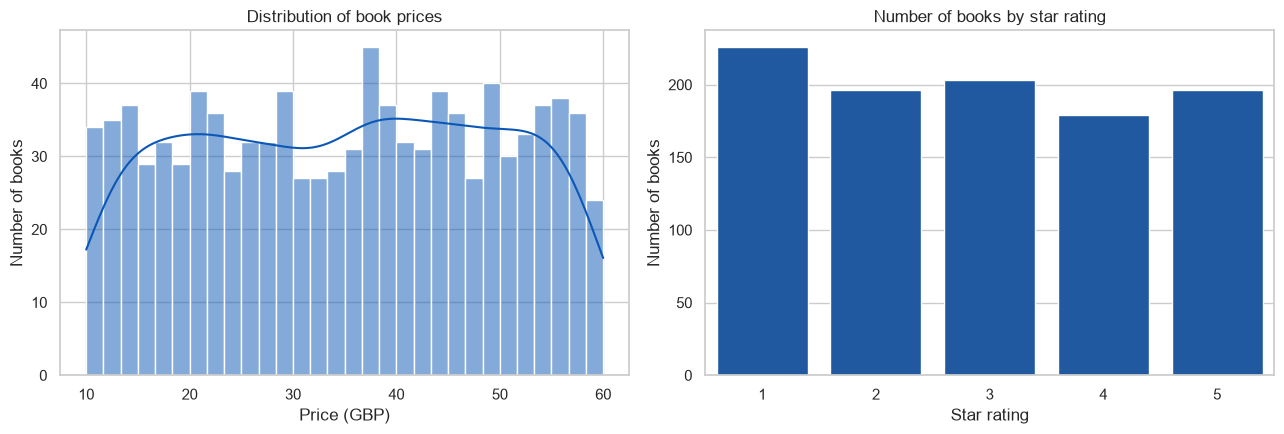

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(clean["price_gbp"], bins=30, kde=True, ax=axes[0], color="#0b57b5")
axes[0].set(title="Distribution of book prices", xlabel="Price (GBP)", ylabel="Number of books")
sns.countplot(x="rating", data=clean, ax=axes[1], color="#0b57b5")
axes[1].set(title="Number of books by star rating", xlabel="Star rating", ylabel="Number of books")
plt.tight_layout(); plt.show()

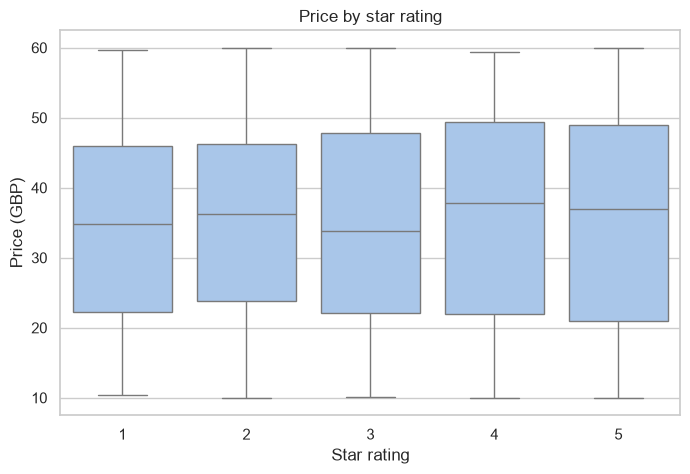

        count   mean  median
rating                      
1         226  34.56   34.77
2         196  34.81   36.22
3         203  34.69   33.78
4         179  36.09   37.80
5         196  35.37   36.90


In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(x="rating", y="price_gbp", data=clean, ax=ax, color="#9ec5f4")
ax.set(title="Price by star rating", xlabel="Star rating", ylabel="Price (GBP)")
plt.show()
print(clean.groupby("rating")["price_gbp"].agg(["count", "mean", "median"]).round(2))

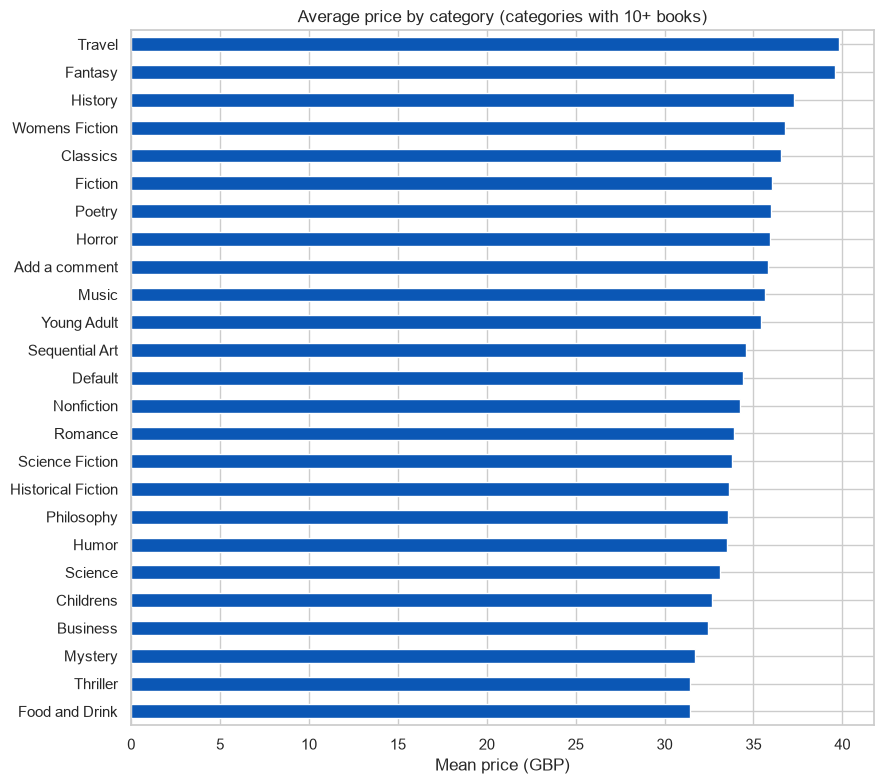

,count,mean,median
category,,,
Travel,11,39.79,38.95
Fantasy,48,39.59,43.58
History,18,37.29,41.29
Womens Fiction,17,36.79,43.58
Classics,19,36.55,35.01
Fiction,65,36.07,39.72
Poetry,19,35.97,38.77
Horror,17,35.95,36.97
Add a comment,67,35.80,36.17


In [9]:
cat_stats = (clean.groupby("category")["price_gbp"].agg(["count", "mean", "median"])
             .sort_values("mean", ascending=False).round(2))
top_cats = cat_stats[cat_stats["count"] >= 10]

fig, ax = plt.subplots(figsize=(9, 8))
top_cats["mean"].sort_values().plot.barh(ax=ax, color="#0b57b5")
ax.set(title="Average price by category (categories with 10+ books)", xlabel="Mean price (GBP)", ylabel="")
plt.tight_layout(); plt.show()
top_cats.head(10)

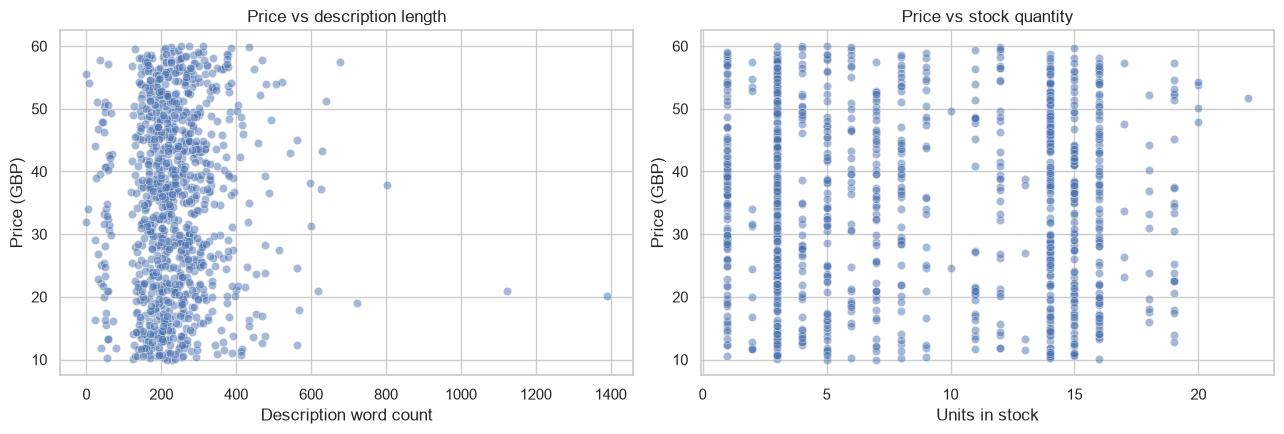

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.scatterplot(x="desc_word_count", y="price_gbp", data=clean, alpha=0.5, ax=axes[0])
axes[0].set(title="Price vs description length", xlabel="Description word count", ylabel="Price (GBP)")
sns.scatterplot(x="stock_qty", y="price_gbp", data=clean, alpha=0.5, ax=axes[1])
axes[1].set(title="Price vs stock quantity", xlabel="Units in stock", ylabel="Price (GBP)")
plt.tight_layout(); plt.show()

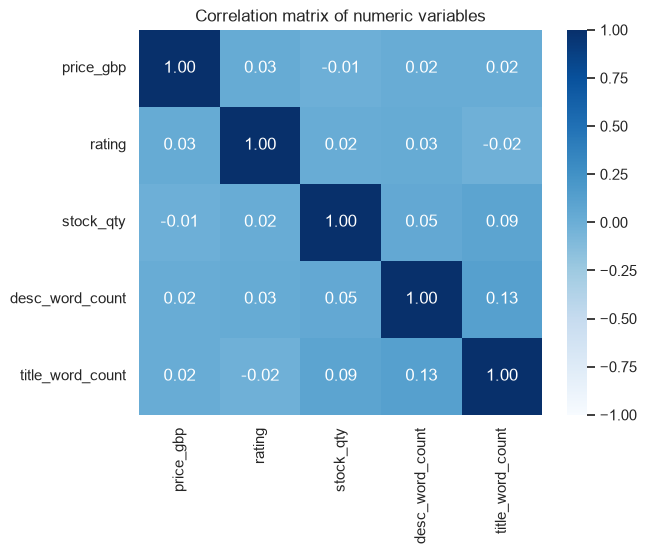

In [11]:
num_cols = ["price_gbp", "rating", "stock_qty", "desc_word_count", "title_word_count"]
plt.figure(figsize=(6.5, 5))
sns.heatmap(clean[num_cols].corr(), annot=True, fmt=".2f", cmap="Blues", vmin=-1, vmax=1)
plt.title("Correlation matrix of numeric variables"); plt.show()

### Interpretation of visual findings
_Fill this in after you run the notebook, using your actual numbers. Suggested prompts:_
- What is the price range, and is the distribution skewed?
- Do higher-rated books cost more, or is there no clear pattern?
- Which categories are most/least expensive on average, and are the differences large relative to the spread within categories?
- Do description length or stock quantity relate to price?
- What do the correlations suggest about how strongly price can be predicted?

## 4. Predictive Modelling: Linear Regression
**Target:** `price_gbp`

**Features and justification**
- `rating`: ordinal 1–5; plausible link between perceived quality and price.
- `stock_qty`: availability may relate to demand/pricing.
- `desc_word_count`, `title_word_count`, `has_description`: simple text-derived signals of how much product information accompanies a book.
- `category` (one-hot encoded; categories with fewer than 15 books grouped as "Other"): genre is the most commonly cited price driver.
- Dropped: `in_stock` and `num_reviews` (almost no variation on this site, so they add nothing), plus identifiers (`title`, `upc`, `url`).

In [12]:
print("in_stock values:", clean["in_stock"].unique(), "| num_reviews values:", clean["num_reviews"].unique())

model_df = clean.copy()
counts = model_df["category"].value_counts()
rare = counts[counts < 15].index
model_df["category_grp"] = model_df["category"].where(~model_df["category"].isin(rare), "Other")

num_features = ["rating", "stock_qty", "desc_word_count", "title_word_count", "has_description"]
X = pd.concat([model_df[num_features],
               pd.get_dummies(model_df["category_grp"], prefix="cat", drop_first=True)], axis=1).astype(float)
y = model_df["price_gbp"]
print("Modelling matrix:", X.shape)

in_stock values: [1] | num_reviews values: [0]
Modelling matrix: (1000, 23)


In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

lr = LinearRegression().fit(X_train, y_train)
pred_train, pred_test = lr.predict(X_train), lr.predict(X_test)

def report(name, y_true, y_pred):
    return {"set": name,
            "MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "R2": r2_score(y_true, y_pred)}

results = pd.DataFrame([report("train", y_train, pred_train), report("test", y_test, pred_test)]).round(3)
print(results)

# Baseline: always predict the training mean
baseline = np.full(len(y_test), y_train.mean())
print("\nBaseline (predict mean) test MAE:", round(mean_absolute_error(y_test, baseline), 3),
      "| RMSE:", round(np.sqrt(mean_squared_error(y_test, baseline)), 3))

cv = cross_val_score(LinearRegression(), X, y, cv=5, scoring="r2")
print("5-fold CV R2:", cv.round(3), "| mean:", cv.mean().round(3))

     set     MAE    RMSE     R2
0  train  12.279  14.255  0.023
1   test  12.841  14.843 -0.049

Baseline (predict mean) test MAE: 12.662 | RMSE: 14.53
5-fold CV R2: [-0.066 -0.029 -0.016 -0.05  -0.071] | mean: -0.046


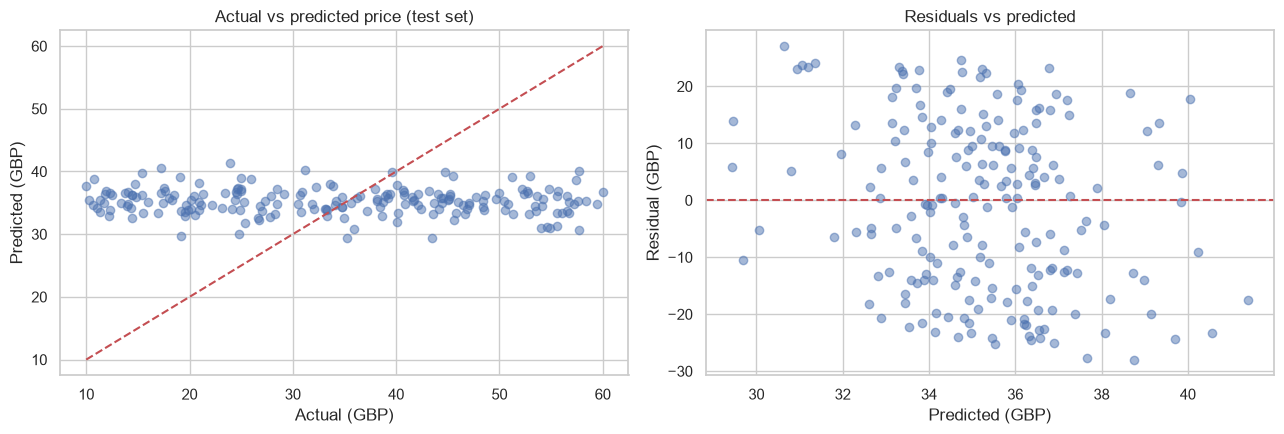

Intercept: 30.514


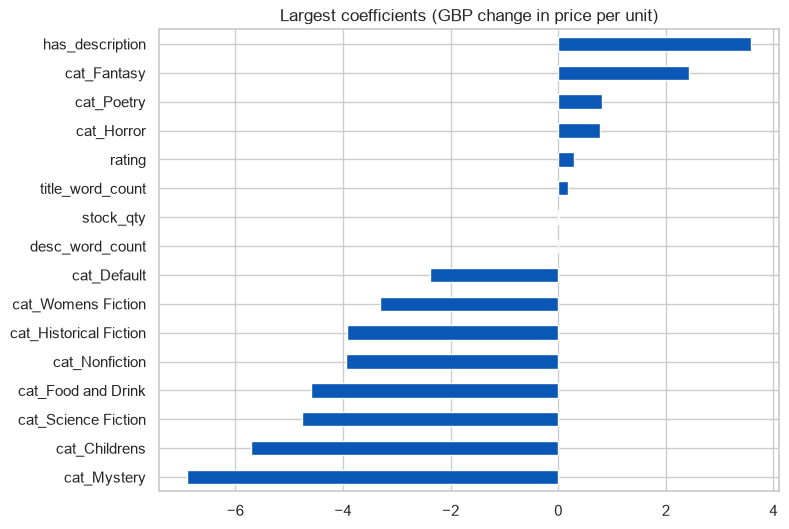

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(y_test, pred_test, alpha=0.5)
lims = [y.min(), y.max()]
axes[0].plot(lims, lims, "r--"); axes[0].set(title="Actual vs predicted price (test set)", xlabel="Actual (GBP)", ylabel="Predicted (GBP)")
resid = y_test - pred_test
axes[1].scatter(pred_test, resid, alpha=0.5); axes[1].axhline(0, color="r", ls="--")
axes[1].set(title="Residuals vs predicted", xlabel="Predicted (GBP)", ylabel="Residual (GBP)")
plt.tight_layout(); plt.show()

coefs = pd.Series(lr.coef_, index=X.columns).sort_values()
print("Intercept:", round(lr.intercept_, 3))
pd.concat([coefs.head(8), coefs.tail(8)]).plot.barh(figsize=(8, 6), color="#0b57b5")
plt.title("Largest coefficients (GBP change in price per unit)"); plt.show()

## 5. Interpretation, Limitations & Recommendations
_Write this after running the notebook, using your real results. Points to cover:_

**Model performance:** report test MAE, RMSE and R² and compare them to the baseline. A low R² is a legitimate finding, not a failure: Books to Scrape is a sandbox site whose prices are not generated by real market dynamics, so predictors like rating and category may explain little.

**Coefficients:** explain the direction and size of the key coefficients in £, and note which are likely not statistically meaningful given the sample size.

**Limitations:** sandbox/synthetic data; few predictors; linearity assumption; categorical grouping; no sales, author, publisher or format data; residual plot shows whether errors are uniform.

**Recommendations for retailers, publishers and buyers:** tie each recommendation to a specific finding, and be honest about how far the evidence supports it.

**Next steps:** regularised regression, log-transforming price, TF-IDF text features, tree-based models for comparison.

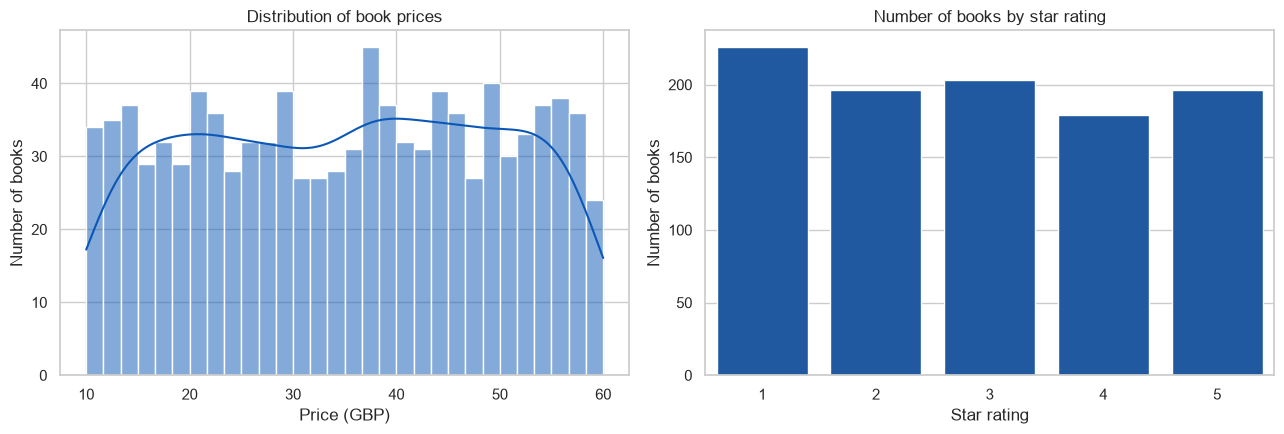

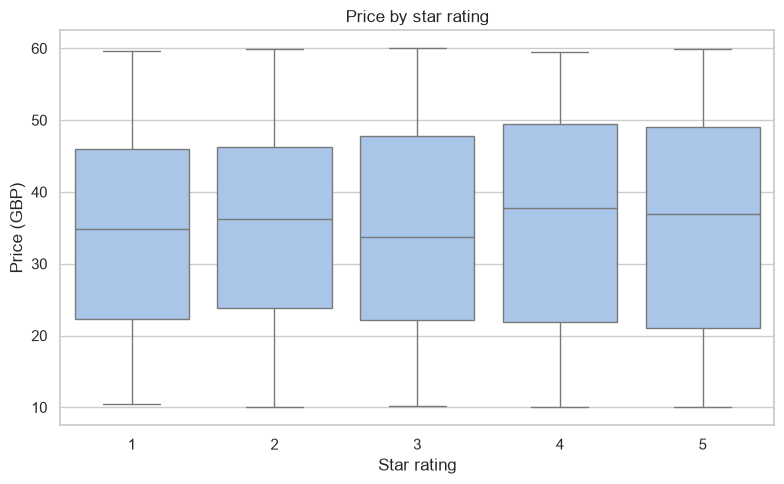

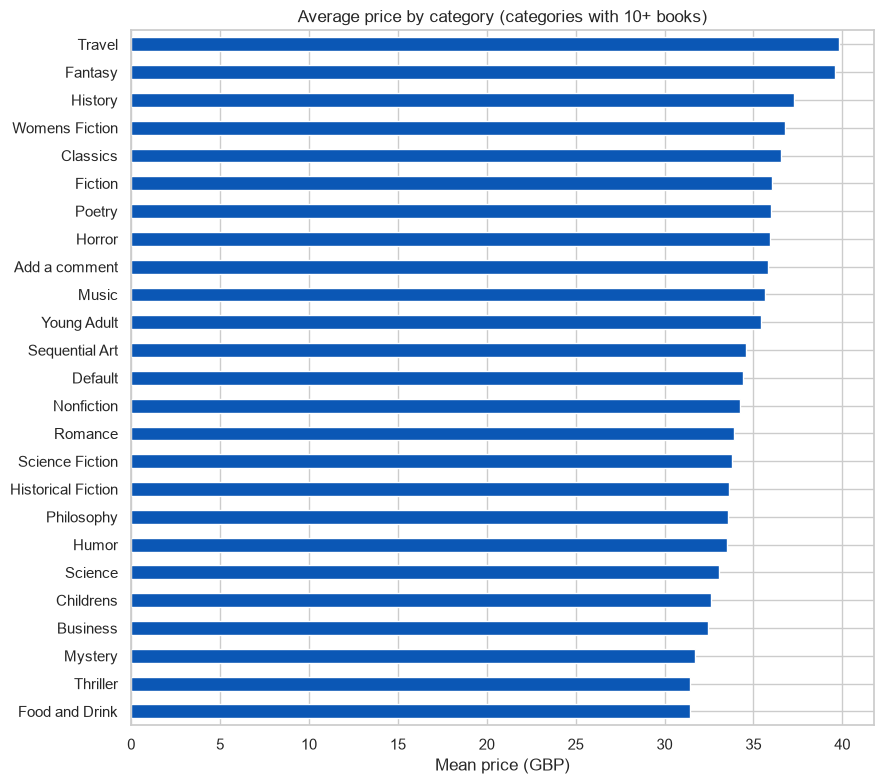

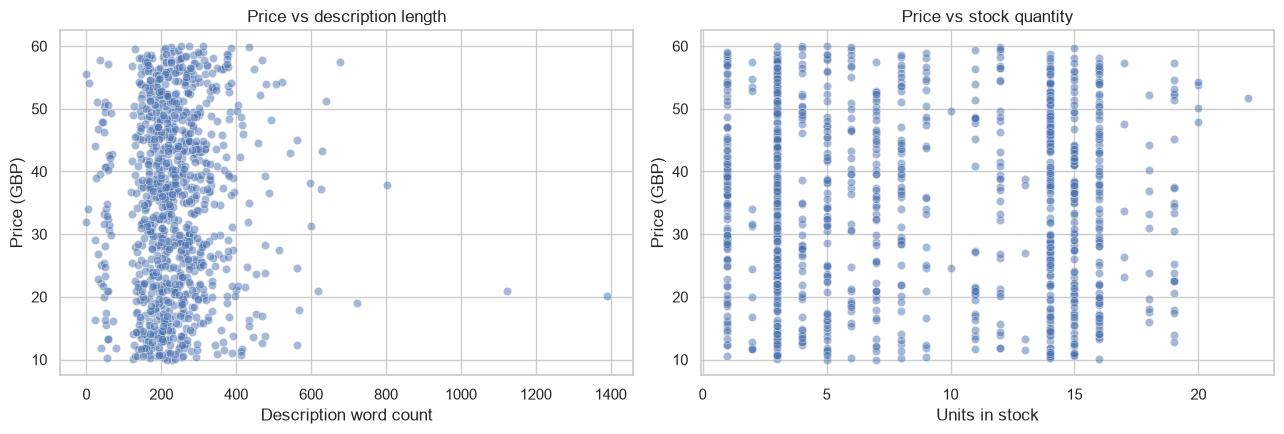

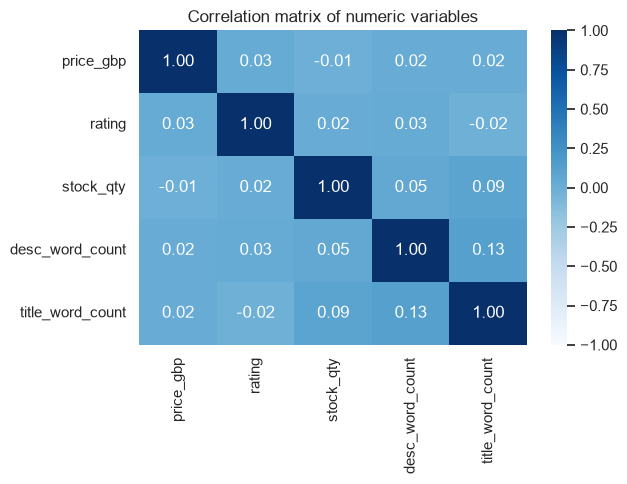

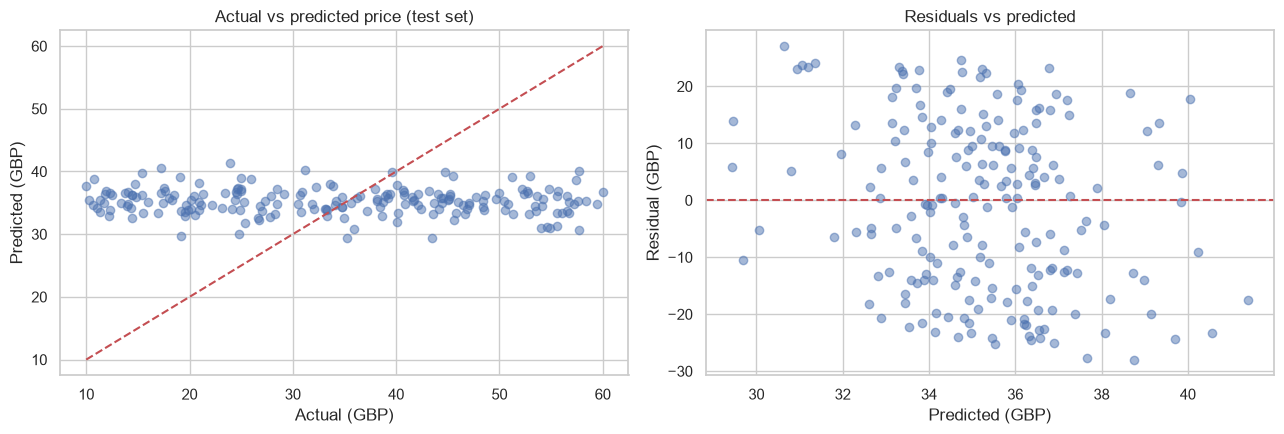

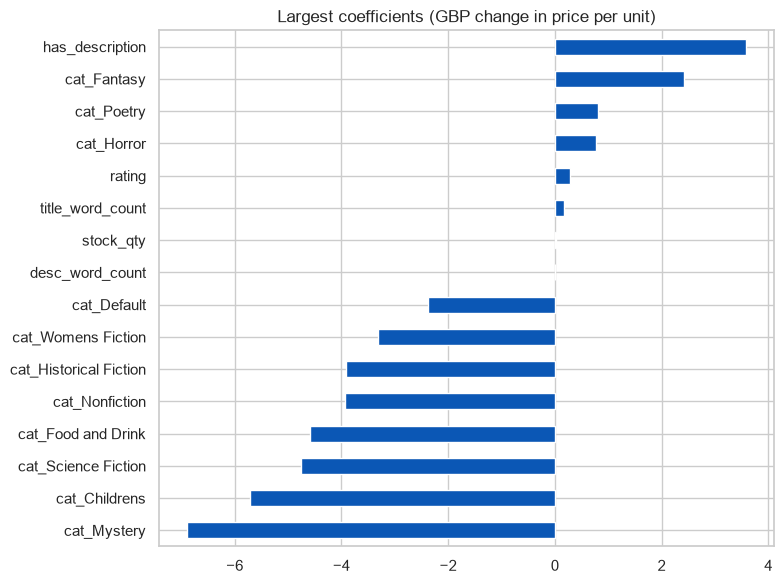

In [15]:
from pathlib import Path
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
plt.style.use("default"); sns.set_theme(style="whitegrid")

def save(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / name, dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()

# Figure 1
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(clean["price_gbp"], bins=30, kde=True, ax=axes[0], color="#0b57b5")
axes[0].set(title="Distribution of book prices", xlabel="Price (GBP)", ylabel="Number of books")
sns.countplot(x="rating", data=clean, ax=axes[1], color="#0b57b5")
axes[1].set(title="Number of books by star rating", xlabel="Star rating", ylabel="Number of books")
save("fig1_price_and_rating_distribution.png")

# Figure 2
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(x="rating", y="price_gbp", data=clean, ax=ax, color="#9ec5f4")
ax.set(title="Price by star rating", xlabel="Star rating", ylabel="Price (GBP)")
save("fig2_price_by_rating.png")

# Figure 3
cs = clean.groupby("category")["price_gbp"].agg(["count", "mean"])
cs = cs[cs["count"] >= 10]
fig, ax = plt.subplots(figsize=(9, 8))
cs["mean"].sort_values().plot.barh(ax=ax, color="#0b57b5")
ax.set(title="Average price by category (categories with 10+ books)", xlabel="Mean price (GBP)", ylabel="")
save("fig3_avg_price_by_category.png")

# Figure 4
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.scatterplot(x="desc_word_count", y="price_gbp", data=clean, alpha=0.5, ax=axes[0])
axes[0].set(title="Price vs description length", xlabel="Description word count", ylabel="Price (GBP)")
sns.scatterplot(x="stock_qty", y="price_gbp", data=clean, alpha=0.5, ax=axes[1])
axes[1].set(title="Price vs stock quantity", xlabel="Units in stock", ylabel="Price (GBP)")
save("fig4_scatter_desc_stock.png")

# Figure 5
cols = ["price_gbp", "rating", "stock_qty", "desc_word_count", "title_word_count"]
plt.figure(figsize=(6.5, 5))
sns.heatmap(clean[cols].corr(), annot=True, fmt=".2f", cmap="Blues", vmin=-1, vmax=1)
plt.title("Correlation matrix of numeric variables")
save("fig5_correlation_heatmap.png")

# Figure 6
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(y_test, pred_test, alpha=0.5)
axes[0].plot([y.min(), y.max()], [y.min(), y.max()], "r--")
axes[0].set(title="Actual vs predicted price (test set)", xlabel="Actual (GBP)", ylabel="Predicted (GBP)")
axes[1].scatter(pred_test, y_test - pred_test, alpha=0.5); axes[1].axhline(0, color="r", ls="--")
axes[1].set(title="Residuals vs predicted", xlabel="Predicted (GBP)", ylabel="Residual (GBP)")
save("fig6_actual_vs_predicted_residuals.png")

# Figure 7
cf = pd.Series(lr.coef_, index=X.columns).sort_values()
pd.concat([cf.head(8), cf.tail(8)]).plot.barh(figsize=(8, 6), color="#0b57b5")
plt.title("Largest coefficients (GBP change in price per unit)")
save("fig7_largest_coefficients.png")